# PHYS3116 Tutorial 5: Functions, the IMF and Distance Measures

In [57]:
import random

import astropy.cosmology.units as cu
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
from scipy.optimize import curve_fit

We will start with an introduction to dictionaries

In [58]:
student = {
    "name": "Alice",
    "age": 20,
    "grade": "HD"
}

In [59]:
student = {
    "name": "Alice",
    "age": 20
}

print(student["name"])

Alice


In [60]:
print(student.get("age"))

20


In [61]:
student["major"] = "Physics"

print(student)

{'name': 'Alice', 'age': 20, 'major': 'Physics'}


In [62]:
student["age"] = 21

print(student)

{'name': 'Alice', 'age': 21, 'major': 'Physics'}


In [63]:
for key, value in student.items():
    print(key, value)

name Alice
age 21
major Physics


In [64]:
student = {
    "name": "Alice",
    "age": 20,
    "major": "Physics"
}

print(student.keys())

dict_keys(['name', 'age', 'major'])


In [65]:
d = {}

d["a"] = 1          # add
d["a"] = 2          # update
print(d["a"])       # access
print(d.keys())     # all keys
print(d.values())   # all values

for key in d.keys():
    print(key)

print()

for key, value in d.items():
    print(key, value)

2
dict_keys(['a'])
dict_values([2])
a

a 2


## Activity:

Simulate a population of stellar streams and estimate how many stars have been detected in each.

In [66]:
streams = {
    "Sagittarius": 0,
    "GSE": 0,
    "Sequoia": 0,
    "Thamnos": 0,
    "Helmi": 0,
    "Jhelum": 0
}

Assign a number of stars to each stream by looping. Hint: use random.randint(10, 500)

In [67]:
for stream in streams.keys():

    streams[stream] = random.randint(10, 500)

print(streams)

{'Sagittarius': 429, 'GSE': 429, 'Sequoia': 96, 'Thamnos': 442, 'Helmi': 79, 'Jhelum': 365}


Find and print the stream with the most amount of stars

In [68]:
largest_stream = ""
largest_num = 0

for stream in streams.keys():

    if streams[stream] > largest_num:

        largest_num = streams[stream]
        largest_stream = stream

print(f"Largest contributor: {largest_stream}")
print(f"Mass: {largest_num} stars")

Largest contributor: Thamnos
Mass: 442 stars


# Astropy

Let's introduce a new Python package, Astropy. As hinted by the name, this package is designed to be used by astronomers. 

In [69]:
# A really useful tool is being able to define units
distance = 30 * u.Mpc
distance

<Quantity 30. Mpc>

In [70]:
time = 20 * u.s
time

<Quantity 20. s>

In [71]:
# Define cosmology
# lets use some approximate values for now.

H0 = 70 # Hubble constant
Om0 = 0.3 # Present day matter desnity


cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)
print(cosmo)

FlatLambdaCDM(H0=70.0 km / (Mpc s), Om0=0.3, Tcmb0=0.0 K, Neff=3.04, m_nu=None, Ob0=None)


In [72]:
# we can use this cosmology to get particular properties at a specified redshift
z = 0.30 * cu.redshift
cosmo.age(z)

<Quantity 10.04867469 Gyr>

In [73]:
# what is the look back time at this redshift?

cosmo.age(0) - cosmo.age(z)

<Quantity 3.41830925 Gyr>

In [74]:
# Can also do for an array of redshifts

cosmo.age([0.5, 1, 1.5] * cu.redshift)

<Quantity [8.42634602, 5.75164694, 4.20073193] Gyr>

In [75]:
# we can also find distances
cosmo.comoving_distance(0)

<Quantity 0. Mpc>

In [76]:
# How far away is the object in today's Universe?
cosmo.comoving_distance(z)

<Quantity 1194.39686972 Mpc>

In [77]:
# How far away was the galaxy when it emitted the light we see today (assuming the galaxy follows the Hubble flow)?
cosmo.comoving_distance(z)/(1+z)

<Quantity 918.76682286 Mpc>

# Exercises

## 1) Plotting Distances
#### a) Imagine you have 10 spectra containing the $H\alpha$ line. Across these spectra you find that the $H\alpha$ line varies between 7,000 and 12,000 Angstroms. Recall that at z = 0,  $\lambda_{H\alpha, rest}$ = 6,563 Angstroms. Pretend that the 10 $H\alpha$ lines are evenly spaced between 7,000 and 12,000 Angstroms. Make a plot of $\lambda_{H\alpha, obs}$ - $\lambda_{H\alpha, rest}$ vs Distance to the object emmitting the spectra. You must use functions to do this where one of the inputs is the array of $\lambda_{H\alpha}$ wavelengths and the output is the distances.

#### b) Using the fitting_func and scipy.curve_fit, fit a curve to the data. For simplicity we will assume a quadratic fit at this redshift range

#### c) Pretend that the telescope can only resolve wavelengths up to (and including) 8,000 Angstroms. What is the largest lookback time that we can observe the $H\alpha$ line.

Text(0, 0.5, 'Comoving Distance (Mpc)')

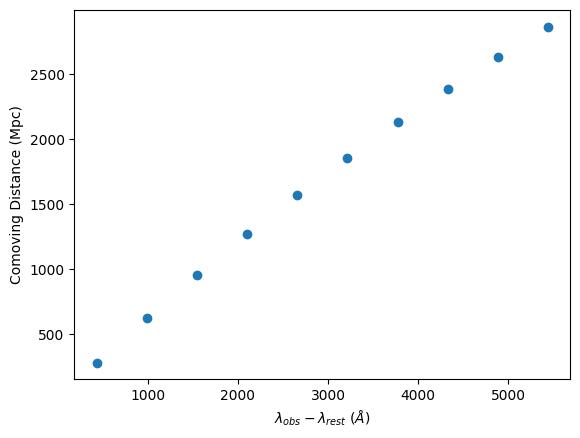

In [78]:
# 1a)

# --- Define cosmology ---
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

lambda_rest = 6563
lambda_obs_array = np.linspace(7000, 12000, 10)

def get_get_distances(lambda_obs, lambda_rest, cosmo):
    z = (lambda_obs - lambda_rest) / lambda_rest
    dist = cosmo.comoving_distance(z * cu.redshift)

    return dist

distances = get_get_distances(lambda_obs_array, lambda_rest, cosmo)

plt.scatter(lambda_obs_array - lambda_rest, distances)
plt.xlabel(r"$\lambda_{obs} - \lambda_{rest}$ $(\AA)$")
plt.ylabel("Comoving Distance (Mpc)")

In [95]:
# 1b)

def fitting_func(lambda_obs, a, b, c, lambda_rest=6563):
    z = lambda_obs/lambda_rest - 1
    return a*z**2 + b*z + c

In [96]:
# popt returns values of a, b used in the fitting_func. pcov is the covariance (error) matrix on the a, b values

popt, pcov = curve_fit(fitting_func, lambda_obs_array, distances, p0=[4000, 0.5, 0])

popt, pcov

(array([-9.73783504e+02,  4.25894126e+03,  3.00227425e+00]),
 array([[ 74.13018602, -66.34785626,  10.46336013],
        [-66.34785626,  62.78211429, -10.88624025],
        [ 10.46336013, -10.88624025,   2.35867053]]))

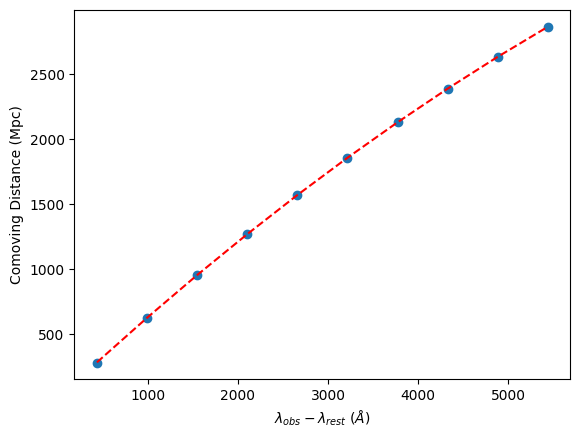

In [ ]:
# plot the data and best fit

plt.scatter(lambda_obs_array - lambda_rest, distances)
plt.xlabel(r"$\lambda_{obs} - \lambda_{rest}$ $(\AA)$")
plt.ylabel("Comoving Distance (Mpc)")

fitted_distances = fitting_func(lambda_obs_array, *popt)
plt.plot(lambda_obs_array - lambda_rest, fitted_distances, color='red', linestyle='--', label="Fit")

In [98]:
# 1c)

z = (8000 - lambda_rest) / lambda_rest
cosmo.age(0) - cosmo.age(z)

<Quantity 2.62930846 Gyr>

# Exercises

## 1) Plotting the Salpeter IMF
#### a) Again using functions, plot the salpeter IMF as a function of mass. Reminder that Function $\propto m^{-2.35}$ for range (0.1Msol - 100Msol)
#### b) Calculate the fraction of the total stellar mass in our galaxy being formed at any one time that is contained in: Stars with mass between 0.1Msol and 0.3Msol (hint: total_mass = np.trapz(m * xi, m))

In [99]:
# 2a)

def salpeter_imf(m, alpha=2.35):
    """
    Salpeter IMF: xi(m) ∝ m^(-alpha)
    m : stellar mass [Msun]
    alpha : slope
    Returns xi(m)
    """
    return m**(-alpha)

Text(0, 0.5, 'IMF $\\xi(m)$')

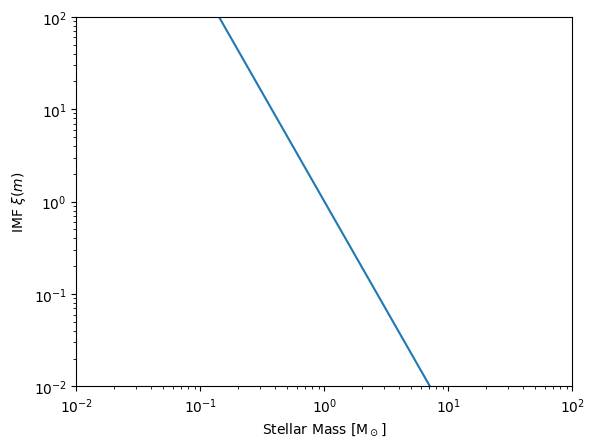

In [100]:
m = np.logspace(-1, 2, 1000)
xi = salpeter_imf(m)

plt.plot(m, xi)

plt.xscale("log")
plt.yscale("log")

plt.xlim(1e-2, 1e2)
plt.ylim(1e-2, 1e2)

plt.xlabel("Stellar Mass [M$_\odot$]")
plt.ylabel(r"IMF $\xi(m)$")

In [85]:
# --- Mass fraction function using np.trapz ---
def mass_fraction(m, m_min, m_max, alpha=2.35):
    """
    Fraction of total stellar mass in [m_min, m_max] using trapezoidal integration.
    """
    # generate mass array
    xi = salpeter_imf(m, alpha)
    
    # total mass
    total_mass = np.trapz(m * xi, m)
    
    # mass in range
    mask = (m >= m_min) & (m <= m_max)
    mass_in_range = np.trapz(m[mask] * xi[mask], m[mask])
    
    # fraction
    frac = mass_in_range / total_mass
    return frac

In [104]:
mass_fraction(m, 0.10, 100)

1.0